# Working with DonorData

patpy represents samples, such as patients, donors or time points, based on their cells. In a typical analysis you end
up with several objects: an AnnData with the cells, a table with the sample metadata, and the output of every method,
like sample representations, distance matrices and embeddings. Keeping all of them in the same sample order is up to
you.

[DonorData](https://github.com/theislab/donordata) keeps them in one object: the cells, one row per sample, and
everything computed per sample, matched by the sample names. Methods in `patpy.tl` accept a DonorData in place of an
AnnData.

In this tutorial we will:

1. build a DonorData from the COMBAT dataset,
2. compute two sample representations and store them in it,
3. evaluate them,
4. select samples and save everything to one file,
5. add a patient level, because some patients in COMBAT gave more than one sample.

## Installation

DonorData is an optional dependency of patpy:

```bash
pip install "patpy[donordata]"
```

In [1]:
import warnings

import numpy as np
import scanpy as sc

import donordata
import patpy

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="patpy")

## Load the data

We use the COMBAT dataset ([COMBAT Consortium, Cell, 2022](https://pubmed.ncbi.nlm.nih.gov/35216673/)): 783k blood
cells from 138 samples of patients with COVID-19, influenza or sepsis, and of healthy volunteers. `patpy.datasets`
downloads it (about 3.7 GB) and returns a `DatasetInfo` with the sample key, the cell type key and the columns that
describe the samples.

In [2]:
adata, info = patpy.datasets.combat(return_dataset_info=True)
adata

AnnData object with n_obs × n_vars = 783677 × 3000
    obs: 'Annotation_cluster_id', 'Annotation_cluster_name', 'Annotation_minor_subset', 'Annotation_major_subset', 'Annotation_cell_type', 'GEX_region', 'QC_ngenes', 'QC_total_UMI', 'QC_pct_mitochondrial', 'QC_scrub_doublet_scores', 'TCR_chain_composition', 'TCR_clone_ID', 'TCR_clone_count', 'TCR_clone_proportion', 'TCR_contains_unproductive', 'TCR_doublet', 'TCR_chain_TRA', 'TCR_v_gene_TRA', 'TCR_d_gene_TRA', 'TCR_j_gene_TRA', 'TCR_c_gene_TRA', 'TCR_productive_TRA', 'TCR_cdr3_TRA', 'TCR_umis_TRA', 'TCR_chain_TRA2', 'TCR_v_gene_TRA2', 'TCR_d_gene_TRA2', 'TCR_j_gene_TRA2', 'TCR_c_gene_TRA2', 'TCR_productive_TRA2', 'TCR_cdr3_TRA2', 'TCR_umis_TRA2', 'TCR_chain_TRB', 'TCR_v_gene_TRB', 'TCR_d_gene_TRB', 'TCR_j_gene_TRB', 'TCR_c_gene_TRB', 'TCR_productive_TRB', 'TCR_chain_TRB2', 'TCR_v_gene_TRB2', 'TCR_d_gene_TRB2', 'TCR_j_gene_TRB2', 'TCR_c_gene_TRB2', 'TCR_productive_TRB2', 'TCR_cdr3_TRB2', 'TCR_umis_TRB2', 'BCR_umis_HC', 'BCR_contig_qc_HC

In [3]:
info

DatasetInfo(n_samples=138, n_cells=783677, n_features=3000, sample_key='scRNASeq_sample_ID', cell_type_key='Annotation_major_subset', sample_metadata_columns=['Source', 'Outcome', 'Death28', 'Institute', 'Pool_ID'])

COMBAT comes with 122 annotations per cell, most of them about T and B cell receptors. We only need the sample and
patient IDs, the cell types and the sample metadata:

In [4]:
keep = [info.sample_key, info.cell_type_key, *info.sample_metadata_columns, "COMBAT_ID", "Age", "Sex"]
adata.obs = adata.obs[keep]

## Build a DonorData

`patpy.pp.as_donordata` takes the same keys as `DatasetInfo`. The sample metadata columns go into a sample table with
one row per sample, instead of being repeated on all 783k cells. Besides the columns from `info`, we keep the patient ID
`COMBAT_ID` and the patient's age and sex, which we need later.

In [5]:
ddata = patpy.pp.as_donordata(
    adata,
    sample_key=info.sample_key,
    sample_metadata_columns=info.sample_metadata_columns + ["COMBAT_ID", "Age", "Sex"],
)
ddata

╔═ DonorData(n_donors=138, n_cells=783,677) ═══════════════════════════════════╗
║ ┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓ ║
║ ┃ D (donors)                         ┃ C (cells, 161..13,918 per donor)    ┃ ║
║ ┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩ ║
║ │ DataFrame with 138 donors × 8      │ AnnData object with n_obs × n_vars  │ ║
║ │ columns                            │ = 783,677 × 3,000                   │ ║
║ │     columns: 'Source', 'Outcome',  │     obs: 'scRNASeq_sample_ID',      │ ║
║ │ 'Death28', 'Institute', 'Pool_ID', │ 'Annotation_major_subset',          │ ║
║ │ 'COMBAT_ID', 'Age', 'Sex'          │ 'Source', 'Outcome', 'Death28',     │ ║
║ │                                    │ 'Institute', 'Pool_ID',             │ ║
║ │                                    │ 'COMBAT_ID', 'Age', 'Sex'           │ ║
║ │                                    │     var: 'gene_ids',                │ ║
║ │                                    │ 'feature_types', 'highly_variable', │ ║
║ │                                    │ 'highly_variable_rank', 'means',    │ ║
║ │                                    │ 'variances', 'variances_norm',      │ ║
║ │                                    │ 'highly_variable_nbatches', 'mt',   │ ║
║ │                                    │ 'ribo', 'n_cells_by_counts',        │ ║
║ │                                    │ 'mean_counts', 'log1p_mean_counts', │ ║
║ │                                    │ 'pct_dropout_by_counts',            │ ║
║ │                                    │ 'total_counts',                     │ ║
║ │                                    │ 'log1p_total_counts'                │ ║
║ │                                    │     uns: 'Institute',               │ ║
║ │                                    │ 'ObjectCreateDate',                 │ ║
║ │                                    │ 'Source_colors', 'Technology',      │ ║
║ │                                    │ 'X_gloscope_cuml_distances',        │ ║
║ │                                    │ 'X_gloscope_pynndescent_distances', │ ║
║ │                                    │ 'X_scpoli', '_scvi_manager_uuid',   │ ║
║ │                                    │ '_scvi_uuid',                       │ ║
║ │                                    │ 'genome_annotation_version',        │ ║
║ │                                    │ 'gloscope_representation',          │ ║
║ │                                    │ 'gloscope_scpoli_distances', 'hvg', │ ║
║ │                                    │ 'log1p', 'neighbors', 'pca',        │ ║
║ │                                    │ 'scpoli_distances',                 │ ║
║ │                                    │ 'scpoli_parameters',                │ ║
║ │                                    │ 'scpoli_samples'                    │ ║
║ │                                    │     obsm: 'X_pca',                  │ ║
║ │                                    │ 'X_scANVI_batch',                   │ ║
║ │                                    │ 'X_scANVI_sample', 'X_scVI_batch',  │ ║
║ │                                    │ 'X_scVI_sample', 'X_scpoli',        │ ║
║ │                                    │ 'X_umap', 'X_umap_source'           │ ║
║ │                                    │     varm: 'PCs'                     │ ║
║ │                                    │     layers: 'X_raw_counts'          │ ║
║ │                                    │     obsp: 'connectivities',         │ ║
║ │                                    │ 'distances'                         │ ║
║ └────────────────────────────────────┴─────────────────────────────────────┘ ║
╚═ donor_id='scRNASeq_sample_ID' ══════════════════════════════════════════════╝

The left column, `D`, is the sample table with 138 rows. DonorData calls its top level "donors", but here every row is
a sample, because we built it with the sample ID as `sample_key`. The right column, `C`, holds the cells.

`ddata.obs` gives the sample table as a DataFrame:

In [6]:
ddata.obs.head()

,Source,Outcome,Death28,Institute,Pool_ID,COMBAT_ID,Age,Sex
scRNASeq_sample_ID,,,,,,,,
G05061-Ja005E-PBCa,COVID_HCW_MILD,6.0,0,Oxford,gPlexC,G05061,5.0,1
G05064-Ja005E-PBCa,COVID_HCW_MILD,6.0,0,Oxford,gPlexA,G05064,5.0,1
G05073-Ja005E-PBCa,COVID_HCW_MILD,6.0,0,Oxford,gPlexJ,G05073,4.0,1
G05077-Ja005E-PBCa,COVID_HCW_MILD,6.0,0,Oxford,gPlexF,G05077,4.0,0
G05078-Ja005E-PBCa,COVID_HCW_MILD,6.0,0,Oxford,gPlexD,G05078,3.0,0


The cells are a regular AnnData in `ddata.C`, so everything from scanpy works on them. The sample columns are kept on
the cells as well, because some methods read them from there.

In [7]:
ddata.C

AnnData object with n_obs × n_vars = 783677 × 3000
    obs: 'scRNASeq_sample_ID', 'Annotation_major_subset', 'Source', 'Outcome', 'Death28', 'Institute', 'Pool_ID', 'COMBAT_ID', 'Age', 'Sex'
    var: 'gene_ids', 'feature_types', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'Institute', 'ObjectCreateDate', 'Source_colors', 'Technology', 'X_gloscope_cuml_distances', 'X_gloscope_pynndescent_distances', 'X_scpoli', '_scvi_manager_uuid', '_scvi_uuid', 'genome_annotation_version', 'gloscope_representation', 'gloscope_scpoli_distances', 'hvg', 'log1p', 'neighbors', 'pca', 'scpoli_distances', 'scpoli_parameters', 'scpoli_samples'
    obsm: 'X_pca', 'X_scANVI_batch', 'X_scANVI_sample', 'X_scVI_batch', 'X_scVI_sample', 'X_scpoli', 'X_umap', 'X_umap_source'
    varm: 'PCs'
    layers: 'X_raw_

## Compute sample representations

A method takes the DonorData in `prepare_anndata`. It reads the cells from `ddata.C` and the sample metadata from the
sample table. After the method has run, `to_donordata` stores its results with the samples:

- the sample representation in `obsm[key]`,
- the distance matrix in `obsp[f"{key}_distances"]`,
- every embedding computed with `embed` in `obsm[f"X_{method}_{key}"]`.

We compute the cell type composition of every sample and a pseudobulk of the scVI embedding.

In [8]:
composition = patpy.tl.CellGroupComposition(
    sample_key=info.sample_key, cell_group_key=info.cell_type_key, apply_clr=True
)
composition.prepare_anndata(ddata)
composition.calculate_distance_matrix()
composition.embed(method="MDS")
composition.to_donordata("composition");

In [9]:
pseudobulk = patpy.tl.Pseudobulk(
    sample_key=info.sample_key, cell_group_key=info.cell_type_key, layer="X_scVI_sample"
)
pseudobulk.prepare_anndata(ddata)
pseudobulk.calculate_distance_matrix()
pseudobulk.embed(method="MDS")
pseudobulk.to_donordata("pseudobulk");

Both representations, their distances and their MDS embeddings are now stored next to the samples:

In [10]:
ddata

╔═ DonorData(n_donors=138, n_cells=783,677) ═══════════════════════════════════╗
║ ┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓ ║
║ ┃ D (donors)                         ┃ C (cells, 161..13,918 per donor)    ┃ ║
║ ┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩ ║
║ │ DataFrame with 138 donors × 8      │ AnnData object with n_obs × n_vars  │ ║
║ │ columns                            │ = 783,677 × 3,000                   │ ║
║ │     columns: 'Source', 'Outcome',  │     obs: 'scRNASeq_sample_ID',      │ ║
║ │ 'Death28', 'Institute', 'Pool_ID', │ 'Annotation_major_subset',          │ ║
║ │ 'COMBAT_ID', 'Age', 'Sex'          │ 'Source', 'Outcome', 'Death28',     │ ║
║ │                                    │ 'Institute', 'Pool_ID',             │ ║
║ │                                    │ 'COMBAT_ID', 'Age', 'Sex'           │ ║
║ │     obsm: 'composition',           │     var: 'gene_ids',                │ ║
║ │ 'X_mds_composition', 'pseudobulk', │ 'feature_types', 'highly_variable', │ ║
║ │ 'X_mds_pseudobulk'                 │ 'highly_variable_rank', 'means',    │ ║
║ │                                    │ 'variances', 'variances_norm',      │ ║
║ │                                    │ 'highly_variable_nbatches', 'mt',   │ ║
║ │                                    │ 'ribo', 'n_cells_by_counts',        │ ║
║ │                                    │ 'mean_counts', 'log1p_mean_counts', │ ║
║ │                                    │ 'pct_dropout_by_counts',            │ ║
║ │                                    │ 'total_counts',                     │ ║
║ │                                    │ 'log1p_total_counts'                │ ║
║ │     obsp: 'composition_distances', │     uns: 'Institute',               │ ║
║ │ 'pseudobulk_distances'             │ 'ObjectCreateDate',                 │ ║
║ │                                    │ 'Source_colors', 'Technology',      │ ║
║ │                                    │ 'X_gloscope_cuml_distances',        │ ║
║ │                                    │ 'X_gloscope_pynndescent_distances', │ ║
║ │                                    │ 'X_scpoli', '_scvi_manager_uuid',   │ ║
║ │                                    │ '_scvi_uuid',                       │ ║
║ │                                    │ 'genome_annotation_version',        │ ║
║ │                                    │ 'gloscope_representation',          │ ║
║ │                                    │ 'gloscope_scpoli_distances', 'hvg', │ ║
║ │                                    │ 'log1p', 'neighbors', 'pca',        │ ║
║ │                                    │ 'scpoli_distances',                 │ ║
║ │                                    │ 'scpoli_parameters',                │ ║
║ │                                    │ 'scpoli_samples',                   │ ║
║ │                                    │ 'composition_parameters',           │ ║
║ │                                    │ 'bulk_parameters'                   │ ║
║ │                                    │     obsm: 'X_pca',                  │ ║
║ │                                    │ 'X_scANVI_batch',                   │ ║
║ │                                    │ 'X_scANVI_sample', 'X_scVI_batch',  │ ║
║ │                                    │ 'X_scVI_sample', 'X_scpoli',        │ ║
║ │                                    │ 'X_umap', 'X_umap_source'           │ ║
║ │                                    │     varm: 'PCs'                     │ ║
║ │                                    │     layers: 'X_raw_counts'          │ ║
║ │                                    │     obsp: 'connectivities',         │ ║
║ │                                    │ 'distances'                         │ ║
║ └────────────────────────────────────┴─────────────────────────────────────┘ ║
╚═ donor_id='scRNASeq_sample_ID' ══════════════════════════════════════════════╝

`ddata.levels["donor"]` returns the samples as an AnnData: the sample table in `obs`, the representations and
embeddings in `obsm` and the distances in `obsp`. scanpy's plotting functions take it directly:

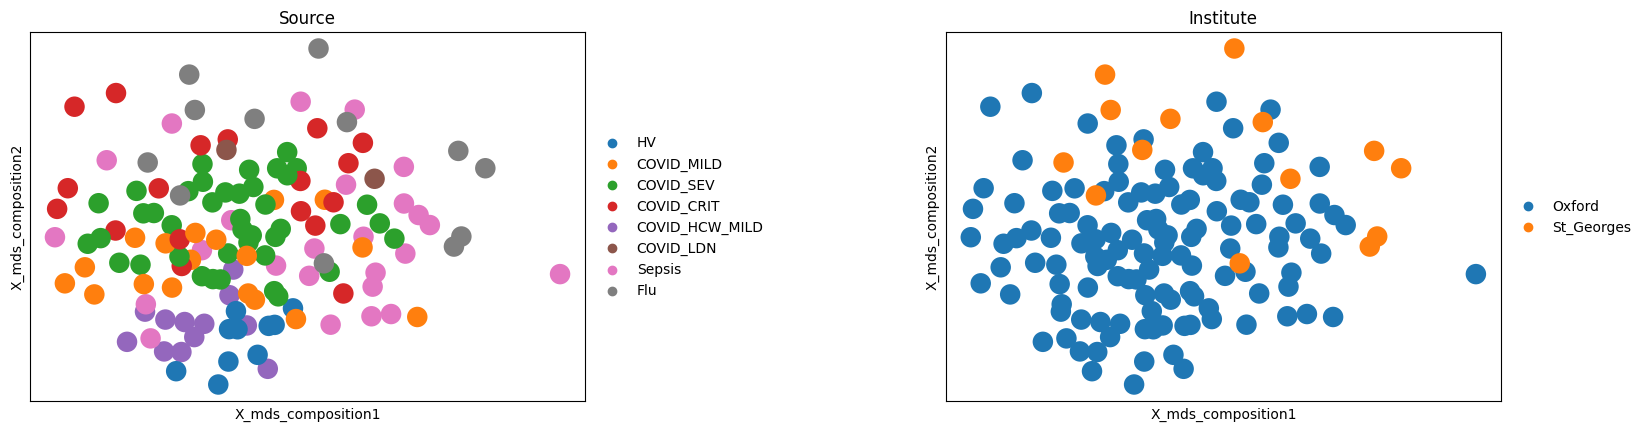

In [11]:
samples = ddata.levels["donor"]
sc.pl.embedding(samples, basis="X_mds_composition", color=["Source", "Institute"], wspace=0.5)

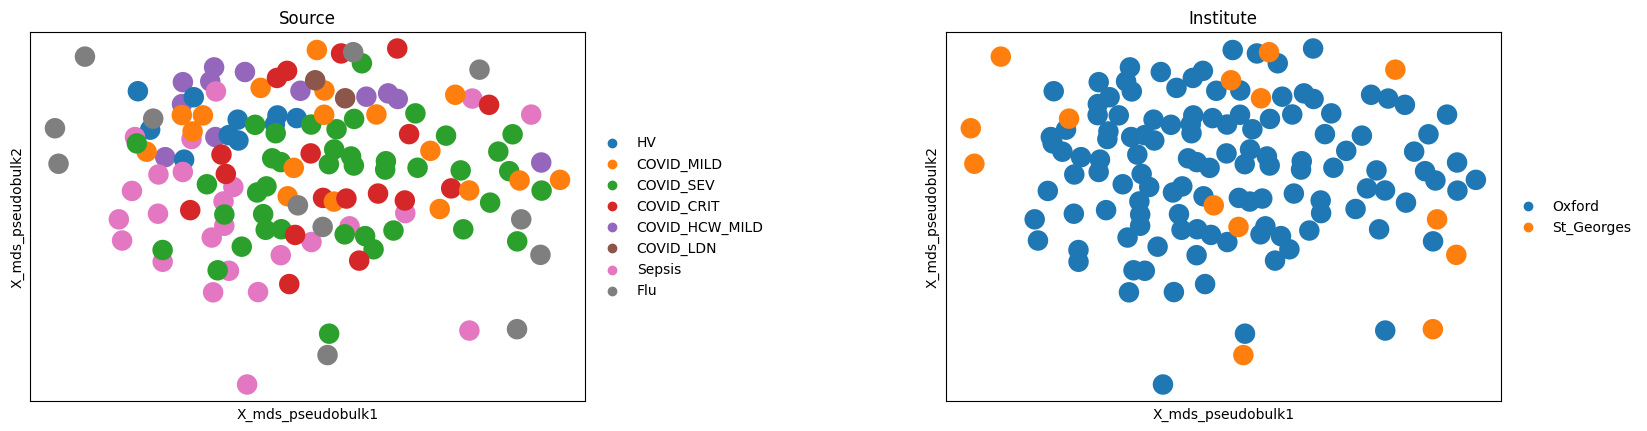

In [12]:
sc.pl.embedding(samples, basis="X_mds_pseudobulk", color=["Source", "Institute"], wspace=0.5)

## Evaluate the representations

The evaluation functions take the same AnnData. `knn_prediction_score` checks how well a covariate can be predicted
from the nearest neighbours of every sample. Clinical covariates should be predictable, technical ones, like the
hospital or the sequencing pool, should not. Technical scores are reversed, so that higher is better for both.

In [13]:
schema = {
    "clinical": {"Outcome": "ranking", "Death28": "classification", "Source": "classification"},
    "technical": {"Institute": "classification", "Pool_ID": "classification"},
}
scores = patpy.tl.knn_prediction_score(samples, schema, representations=["composition", "pseudobulk"], n_neighbors=5)
scores.pivot_table(index=["covariate_type", "covariate"], columns="representation", values="score").round(2)

representation            composition  pseudobulk
covariate_type covariate                         
clinical       Death28           0.00        0.10
               Outcome           0.67        0.57
               Source            0.20        0.18
technical      Institute         0.83        1.00
               Pool_ID           1.00        0.71

## Select samples

Selecting samples selects their cells and their stored results with them. Here we keep everyone except the healthy
volunteers:

In [14]:
patients = ddata.filter_donors("Source != 'HV'")
patients

╔═ DonorData(n_donors=128, n_cells=696,473) ═══════════════════════════════════╗
║ ┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓ ║
║ ┃ D (donors)                         ┃ C (cells, 161..13,918 per donor)    ┃ ║
║ ┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩ ║
║ │ DataFrame with 128 donors × 8      │ AnnData object with n_obs × n_vars  │ ║
║ │ columns                            │ = 696,473 × 3,000                   │ ║
║ │     columns: 'Source', 'Outcome',  │     obs: 'scRNASeq_sample_ID',      │ ║
║ │ 'Death28', 'Institute', 'Pool_ID', │ 'Annotation_major_subset',          │ ║
║ │ 'COMBAT_ID', 'Age', 'Sex'          │ 'Source', 'Outcome', 'Death28',     │ ║
║ │                                    │ 'Institute', 'Pool_ID',             │ ║
║ │                                    │ 'COMBAT_ID', 'Age', 'Sex'           │ ║
║ │     obsm: 'composition',           │     var: 'gene_ids',                │ ║
║ │ 'X_mds_composition', 'pseudobulk', │ 'feature_types', 'highly_variable', │ ║
║ │ 'X_mds_pseudobulk'                 │ 'highly_variable_rank', 'means',    │ ║
║ │                                    │ 'variances', 'variances_norm',      │ ║
║ │                                    │ 'highly_variable_nbatches', 'mt',   │ ║
║ │                                    │ 'ribo', 'n_cells_by_counts',        │ ║
║ │                                    │ 'mean_counts', 'log1p_mean_counts', │ ║
║ │                                    │ 'pct_dropout_by_counts',            │ ║
║ │                                    │ 'total_counts',                     │ ║
║ │                                    │ 'log1p_total_counts'                │ ║
║ │     obsp: 'composition_distances', │     uns: 'Institute',               │ ║
║ │ 'pseudobulk_distances'             │ 'ObjectCreateDate',                 │ ║
║ │                                    │ 'Source_colors', 'Technology',      │ ║
║ │                                    │ 'X_gloscope_cuml_distances',        │ ║
║ │                                    │ 'X_gloscope_pynndescent_distances', │ ║
║ │                                    │ 'X_scpoli', '_scvi_manager_uuid',   │ ║
║ │                                    │ '_scvi_uuid',                       │ ║
║ │                                    │ 'genome_annotation_version',        │ ║
║ │                                    │ 'gloscope_representation',          │ ║
║ │                                    │ 'gloscope_scpoli_distances', 'hvg', │ ║
║ │                                    │ 'log1p', 'neighbors', 'pca',        │ ║
║ │                                    │ 'scpoli_distances',                 │ ║
║ │                                    │ 'scpoli_parameters',                │ ║
║ │                                    │ 'scpoli_samples',                   │ ║
║ │                                    │ 'composition_parameters',           │ ║
║ │                                    │ 'bulk_parameters'                   │ ║
║ │                                    │     obsm: 'X_pca',                  │ ║
║ │                                    │ 'X_scANVI_batch',                   │ ║
║ │                                    │ 'X_scANVI_sample', 'X_scVI_batch',  │ ║
║ │                                    │ 'X_scVI_sample', 'X_scpoli',        │ ║
║ │                                    │ 'X_umap', 'X_umap_source'           │ ║
║ │                                    │     varm: 'PCs'                     │ ║
║ │                                    │     layers: 'X_raw_counts'          │ ║
║ │                                    │     obsp: 'connectivities',         │ ║
║ │                                    │ 'distances'                         │ ║
║ └────────────────────────────────────┴─────────────────────────────────────┘ ║
╚═ donor_id='scRNASeq_sample_ID' ══════════════════════════════════════════════╝

The distance matrices are cut down to the selected samples, in the order of the new sample table:

In [15]:
positions = ddata.obs_names.get_indexer(patients.obs_names)
full = ddata.obsp["composition_distances"]
np.allclose(patients.obsp["composition_distances"], full[np.ix_(positions, positions)])

True

So we can evaluate the representations on the patients alone, without computing them again:

In [16]:
patient_scores = patpy.tl.knn_prediction_score(
    patients.levels["donor"], schema, representations=["composition", "pseudobulk"], n_neighbors=5
)
patient_scores.pivot_table(index=["covariate_type", "covariate"], columns="representation", values="score").round(2)

representation            composition  pseudobulk
covariate_type covariate                         
clinical       Death28           0.00        0.09
               Outcome           0.56        0.45
               Source            0.23        0.13
technical      Institute         0.84        1.00
               Pool_ID           1.00        0.70

## Save and load

Cells, sample table and results are written to one file and read back as they were:

In [17]:
ddata.write_h5_dd("data/combat.dd.h5")
ddata = donordata.read_dd("data/combat.dd.h5")
ddata

╔═ DonorData(n_donors=138, n_cells=783,677) ═══════════════════════════════════╗
║ ┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓ ║
║ ┃ D (donors)                         ┃ C (cells, 161..13,918 per donor)    ┃ ║
║ ┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩ ║
║ │ DataFrame with 138 donors × 8      │ AnnData object with n_obs × n_vars  │ ║
║ │ columns                            │ = 783,677 × 3,000                   │ ║
║ │     columns: 'Source', 'Outcome',  │     obs: 'scRNASeq_sample_ID',      │ ║
║ │ 'Death28', 'Institute', 'Pool_ID', │ 'Annotation_major_subset',          │ ║
║ │ 'COMBAT_ID', 'Age', 'Sex'          │ 'Source', 'Outcome', 'Death28',     │ ║
║ │                                    │ 'Institute', 'Pool_ID',             │ ║
║ │                                    │ 'COMBAT_ID', 'Age', 'Sex'           │ ║
║ │     obsm: 'X_mds_composition',     │     var: 'gene_ids',                │ ║
║ │ 'X_mds_pseudobulk', 'composition', │ 'feature_types', 'highly_variable', │ ║
║ │ 'pseudobulk'                       │ 'highly_variable_rank', 'means',    │ ║
║ │                                    │ 'variances', 'variances_norm',      │ ║
║ │                                    │ 'highly_variable_nbatches', 'mt',   │ ║
║ │                                    │ 'ribo', 'n_cells_by_counts',        │ ║
║ │                                    │ 'mean_counts', 'log1p_mean_counts', │ ║
║ │                                    │ 'pct_dropout_by_counts',            │ ║
║ │                                    │ 'total_counts',                     │ ║
║ │                                    │ 'log1p_total_counts'                │ ║
║ │     obsp: 'composition_distances', │     uns: 'Institute',               │ ║
║ │ 'pseudobulk_distances'             │ 'ObjectCreateDate',                 │ ║
║ │                                    │ 'Source_colors', 'Technology',      │ ║
║ │                                    │ 'X_gloscope_cuml_distances',        │ ║
║ │                                    │ 'X_gloscope_pynndescent_distances', │ ║
║ │                                    │ 'X_scpoli', '_scvi_manager_uuid',   │ ║
║ │                                    │ '_scvi_uuid', 'bulk_parameters',    │ ║
║ │                                    │ 'composition_parameters',           │ ║
║ │                                    │ 'genome_annotation_version',        │ ║
║ │                                    │ 'gloscope_representation',          │ ║
║ │                                    │ 'gloscope_scpoli_distances', 'hvg', │ ║
║ │                                    │ 'log1p', 'neighbors', 'pca',        │ ║
║ │                                    │ 'scpoli_distances',                 │ ║
║ │                                    │ 'scpoli_parameters',                │ ║
║ │                                    │ 'scpoli_samples'                    │ ║
║ │                                    │     obsm: 'X_pca',                  │ ║
║ │                                    │ 'X_scANVI_batch',                   │ ║
║ │                                    │ 'X_scANVI_sample', 'X_scVI_batch',  │ ║
║ │                                    │ 'X_scVI_sample', 'X_scpoli',        │ ║
║ │                                    │ 'X_umap', 'X_umap_source'           │ ║
║ │                                    │     varm: 'PCs'                     │ ║
║ │                                    │     layers: 'X_raw_counts'          │ ║
║ │                                    │     obsp: 'connectivities',         │ ║
║ │                                    │ 'distances'                         │ ║
║ └────────────────────────────────────┴─────────────────────────────────────┘ ║
╚═ donor_id='scRNASeq_sample_ID' ══════════════════════════════════════════════╝

## Patients with several samples

Some patients in COMBAT gave more than one sample. With the samples as the only level, those samples count as
independent data points, for example in the evaluation above. `nest` adds the patients as a level above the samples:
columns that are the same for all samples of a patient move to a patient table, columns that differ between samples
stay with the samples.

In [18]:
by_patient = ddata.nest("COMBAT_ID")
by_patient

╔═ DonorData(n_donors=122, n_samples=138, n_cells=783,677) ════════════════════╗
║ ┏━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓ ║
║ ┃                        ┃ S (samples, 1..3 per   ┃ C (cells, 161..13,918  ┃ ║
║ ┃ D (donors)             ┃ donor)                 ┃ per sample)            ┃ ║
║ ┡━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩ ║
║ │ DataFrame with 122     │ DataFrame with 138     │ AnnData object with    │ ║
║ │ donors × 5 columns     │ samples × 3 columns    │ n_obs × n_vars =       │ ║
║ │                        │                        │ 783,677 × 3,000        │ ║
║ │     columns:           │     columns: 'Source', │     obs:               │ ║
║ │ 'Outcome', 'Death28',  │ 'Pool_ID', 'COMBAT_ID' │ 'scRNASeq_sample_ID',  │ ║
║ │ 'Institute', 'Age',    │                        │ 'Annotation_major_sub… │ ║
║ │ 'Sex'                  │                        │ 'Source', 'Outcome',   │ ║
║ │                        │                        │ 'Death28',             │ ║
║ │                        │                        │ 'Institute',           │ ║
║ │                        │                        │ 'Pool_ID',             │ ║
║ │                        │                        │ 'COMBAT_ID', 'Age',    │ ║
║ │                        │                        │ 'Sex'                  │ ║
║ │                        │     obsm:              │     var: 'gene_ids',   │ ║
║ │                        │ 'X_mds_composition',   │ 'feature_types',       │ ║
║ │                        │ 'X_mds_pseudobulk',    │ 'highly_variable',     │ ║
║ │                        │ 'composition',         │ 'highly_variable_rank… │ ║
║ │                        │ 'pseudobulk'           │ 'means', 'variances',  │ ║
║ │                        │                        │ 'variances_norm',      │ ║
║ │                        │                        │ 'highly_variable_nbat… │ ║
║ │                        │                        │ 'mt', 'ribo',          │ ║
║ │                        │                        │ 'n_cells_by_counts',   │ ║
║ │                        │                        │ 'mean_counts',         │ ║
║ │                        │                        │ 'log1p_mean_counts',   │ ║
║ │                        │                        │ 'pct_dropout_by_count… │ ║
║ │                        │                        │ 'total_counts',        │ ║
║ │                        │                        │ 'log1p_total_counts'   │ ║
║ │                        │     obsp:              │     uns: 'Institute',  │ ║
║ │                        │ 'composition_distance… │ 'ObjectCreateDate',    │ ║
║ │                        │ 'pseudobulk_distances' │ 'Source_colors',       │ ║
║ │                        │                        │ 'Technology',          │ ║
║ │                        │                        │ 'X_gloscope_cuml_dist… │ ║
║ │                        │                        │ 'X_gloscope_pynndesce… │ ║
║ │                        │                        │ 'X_scpoli',            │ ║
║ │                        │                        │ '_scvi_manager_uuid',  │ ║
║ │                        │                        │ '_scvi_uuid',          │ ║
║ │                        │                        │ 'bulk_parameters',     │ ║
║ │                        │                        │ 'composition_paramete… │ ║
║ │                        │                        │ 'genome_annotation_ve… │ ║
║ │                        │                        │ 'gloscope_representat… │ ║
║ │                        │                        │ 'gloscope_scpoli_dist… │ ║
║ │                        │                        │ 'hvg', 'log1p',        │ ║
║ │                        │                        │ 'neighbors', 'pca',    │ ║
║ │                        │                        │ 'scpoli_distances',    │ ║
║ │                        │                        │ 'scpoli_parameters',   │ ║
║ │                        │   

In [19]:
by_patient.D.head()

,Outcome,Death28,Institute,Age,Sex
COMBAT_ID,,,,,
G05061,6.0,0,Oxford,5.0,1
G05064,6.0,0,Oxford,5.0,1
G05073,6.0,0,Oxford,4.0,1
G05077,6.0,0,Oxford,4.0,0
G05078,6.0,0,Oxford,3.0,0


In [20]:
by_patient.S.head()

,Source,Pool_ID,COMBAT_ID
scRNASeq_sample_ID,,,
G05061-Ja005E-PBCa,COVID_HCW_MILD,gPlexC,G05061
G05064-Ja005E-PBCa,COVID_HCW_MILD,gPlexA,G05064
G05073-Ja005E-PBCa,COVID_HCW_MILD,gPlexJ,G05073
G05077-Ja005E-PBCa,COVID_HCW_MILD,gPlexF,G05077
G05078-Ja005E-PBCa,COVID_HCW_MILD,gPlexD,G05078


In [21]:
samples_per_patient = by_patient.S.groupby("COMBAT_ID", observed=True).size()
samples_per_patient[samples_per_patient > 1]

COMBAT_ID
N00023    2
N00028    2
S00005    2
S00033    3
S00042    2
S00045    3
S00048    2
S00052    2
S00056    2
S00081    2
S00109    3
S00124    2
S00129    2
dtype: int64

The representations we computed per sample moved with the samples. `sample_key` decides what a method treats as
samples: the sample ID gives one representation per sample, the patient ID pools the cells of all samples of a
patient. Any other key raises an error.

In [22]:
per_patient = patpy.tl.CellGroupComposition(sample_key="COMBAT_ID", cell_group_key=info.cell_type_key, apply_clr=True)
per_patient.prepare_anndata(by_patient)
per_patient.calculate_distance_matrix()
per_patient.embed(method="MDS")
per_patient.to_donordata("composition")
by_patient

╔═ DonorData(n_donors=122, n_samples=138, n_cells=783,677) ════════════════════╗
║ ┏━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓ ║
║ ┃                        ┃ S (samples, 1..3 per   ┃ C (cells, 161..13,918  ┃ ║
║ ┃ D (donors)             ┃ donor)                 ┃ per sample)            ┃ ║
║ ┡━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩ ║
║ │ DataFrame with 122     │ DataFrame with 138     │ AnnData object with    │ ║
║ │ donors × 5 columns     │ samples × 3 columns    │ n_obs × n_vars =       │ ║
║ │                        │                        │ 783,677 × 3,000        │ ║
║ │     columns:           │     columns: 'Source', │     obs:               │ ║
║ │ 'Outcome', 'Death28',  │ 'Pool_ID', 'COMBAT_ID' │ 'scRNASeq_sample_ID',  │ ║
║ │ 'Institute', 'Age',    │                        │ 'Annotation_major_sub… │ ║
║ │ 'Sex'                  │                        │ 'Source', 'Outcome',   │ ║
║ │                        │                        │ 'Death28',             │ ║
║ │                        │                        │ 'Institute',           │ ║
║ │                        │                        │ 'Pool_ID',             │ ║
║ │                        │                        │ 'COMBAT_ID', 'Age',    │ ║
║ │                        │                        │ 'Sex'                  │ ║
║ │     obsm:              │     obsm:              │     var: 'gene_ids',   │ ║
║ │ 'composition',         │ 'X_mds_composition',   │ 'feature_types',       │ ║
║ │ 'X_mds_composition'    │ 'X_mds_pseudobulk',    │ 'highly_variable',     │ ║
║ │                        │ 'composition',         │ 'highly_variable_rank… │ ║
║ │                        │ 'pseudobulk'           │ 'means', 'variances',  │ ║
║ │                        │                        │ 'variances_norm',      │ ║
║ │                        │                        │ 'highly_variable_nbat… │ ║
║ │                        │                        │ 'mt', 'ribo',          │ ║
║ │                        │                        │ 'n_cells_by_counts',   │ ║
║ │                        │                        │ 'mean_counts',         │ ║
║ │                        │                        │ 'log1p_mean_counts',   │ ║
║ │                        │                        │ 'pct_dropout_by_count… │ ║
║ │                        │                        │ 'total_counts',        │ ║
║ │                        │                        │ 'log1p_total_counts'   │ ║
║ │     obsp:              │     obsp:              │     uns: 'Institute',  │ ║
║ │ 'composition_distance… │ 'composition_distance… │ 'ObjectCreateDate',    │ ║
║ │                        │ 'pseudobulk_distances' │ 'Source_colors',       │ ║
║ │                        │                        │ 'Technology',          │ ║
║ │                        │                        │ 'X_gloscope_cuml_dist… │ ║
║ │                        │                        │ 'X_gloscope_pynndesce… │ ║
║ │                        │                        │ 'X_scpoli',            │ ║
║ │                        │                        │ '_scvi_manager_uuid',  │ ║
║ │                        │                        │ '_scvi_uuid',          │ ║
║ │                        │                        │ 'bulk_parameters',     │ ║
║ │                        │                        │ 'composition_paramete… │ ║
║ │                        │                        │ 'genome_annotation_ve… │ ║
║ │                        │                        │ 'gloscope_representat… │ ║
║ │                        │                        │ 'gloscope_scpoli_dist… │ ║
║ │                        │                        │ 'hvg', 'log1p',        │ ║
║ │                        │                        │ 'neighbors', 'pca',    │ ║
║ │                        │                        │ 'scpoli_distances',    │ ║
║ │                        │                        │ 'scpoli_parameters',   │ ║
║ │                        │   

On the patient level, every patient counts once in the evaluation:

In [23]:
patient_schema = {
    "clinical": {"Outcome": "ranking", "Death28": "classification"},
    "technical": {"Institute": "classification"},
}
patient_level_scores = patpy.tl.knn_prediction_score(
    by_patient.levels["donor"], patient_schema, representations=["composition"], n_neighbors=5
)
patient_level_scores[["covariate_type", "covariate", "metric", "score"]].round(2)

,covariate_type,covariate,metric,score
0,clinical,Outcome,spearman_r,0.75
1,clinical,Death28,f1_macro_calibrated,0.02
2,technical,Institute,f1_macro_calibrated,0.84


If you need patient covariates next to per-sample results, `by_patient.flatten()` makes the samples the top level again
and repeats the patient columns for every sample. Patients with several samples then count more than once.

To learn more about DonorData itself, see its [documentation](https://github.com/theislab/donordata).